# Compare peak method 400 nm and 800 nm


slope 1 m = -0.0247
slope 2 m = -0.0093


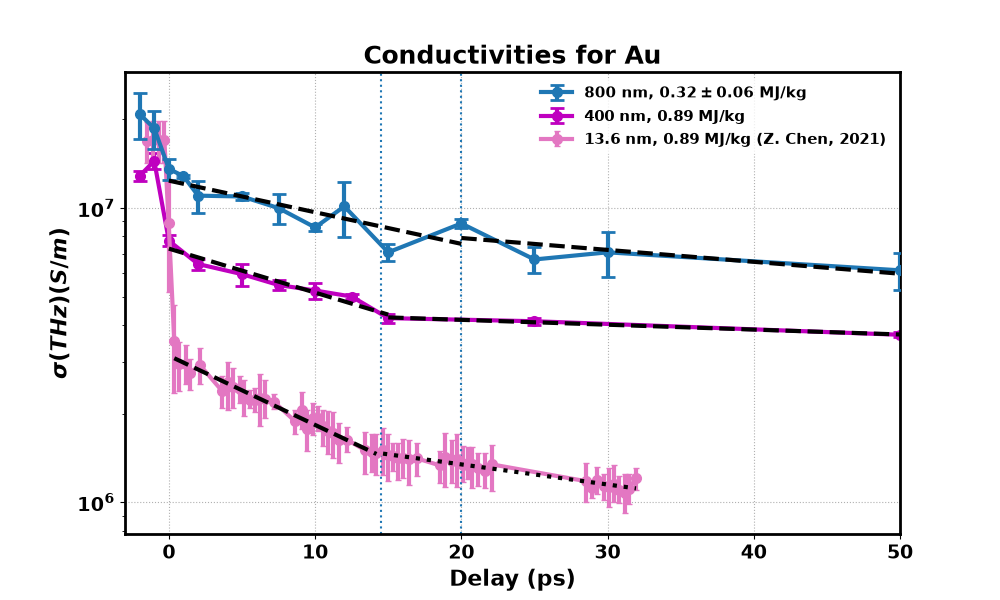

In [5]:
import json
import matplotlib.pyplot as plt
from pprint import pprint
import numpy as np
from myfuncs.utility import zhijiang, exp_slope, conductivity_13_6
%matplotlib widget

plt.rcParams.update({
    'axes.titlesize': 18,     # Title size
    'axes.labelsize': 16,     # X and Y label size
    'xtick.labelsize': 14,    # X tick size
    'ytick.labelsize': 14,    # Y tick size
    'legend.fontsize': 11     # Legend size
})
plt.rcParams['axes.linewidth'] = 2
plt.rcParams['font.weight'] = 'bold'

file_root = '/Users/yuewang/SLAC/goldthz/Au_data/code/'
def load(filename):
    with open(filename,"r") as file:
        raw = json.load(file)
    data = {float(key): value for key, value in raw.items()}
    return data


sigma800 = load(file_root + 'Peak method/800_nm_peaks.json')
sigma400 = load(file_root + 'Peak method/400_nm_peaks.json')
FFTsigma400 = load(file_root + 'FFT method/400_nm_FFT.json')
FFT800 = load(file_root + 'FFT method/800_nm_FFT_full.json')
FFT800_5 = load(file_root + 'FFT method/800_nm_FFT_5ps.json')
FFT800_4 = load(file_root + 'FFT method/800_nm_FFT_4ps.json')

# pre conductivities
PEAK_PRE400 = load(file_root + 'Peak method/400_nm_peaks_pre.json')
PEAK_PRE400.pop(10.0, None)
PEAK_PRE800 = load(file_root + 'Peak method/800_nm_peaks_pre.json')


def makeGraph(data, label):
    plt.errorbar(data.keys(), [v["mean"] for v in data.values()], yerr=[v["std"] for v in data.values()],fmt="-o", capsize=3, label=f"{label}")
    print(label)
    pprint(data)

plt.figure(figsize=(10,6))
#makeGraph(PEAK_PRE400, "pre, 400 nm, peak method")
#makeGraph(PEAK_PRE800, "pre, 800 nm, peak method")

#plt.errorbar(sigma800.keys(), [v["mean"] for v in sigma800.values()], yerr=[v["std"] for v in sigma800.values()], fmt="-o", capsize=3, label="800 nm, peak")
#plt.errorbar(sigma400.keys(), [v["mean"] for v in sigma400.values()], yerr=[v["std"] for v in sigma400.values()], color="g",fmt="-o", capsize=3, label="400 nm, peak")
plt.errorbar(FFT800_4.keys(), [v["mean"] for v in FFT800_4.values()], yerr=[v["std"] for v in FFT800_4.values()], fmt="-o", capsize=5, capthick=2, markersize=7, label=r"800 nm, $0.32 \pm 0.06$ MJ/kg", lw=3, zorder=3)
plt.errorbar(FFTsigma400.keys(), [v["mean"] for v in FFTsigma400.values()], yerr=[v["std"] for v in FFTsigma400.values()], color="m", fmt="-o", capsize=5, capthick=2, markersize=7, label="400 nm, 0.89 MJ/kg", lw=3)
#plt.errorbar(FFT800.keys(), [v["mean"] for v in FFT800.values()], yerr=[v["std"] for v in FFT800.values()], fmt="-o", capsize=3, label="800 nm, FFT")
#plt.errorbar(FFT800_5.keys(), [v["mean"] for v in FFT800_5.values()], yerr=[v["std"] for v in FFT800_5.values()], fmt="-o", capsize=3, label="800 nm, FFT (5ps)")

delay, sigma, upErr, lowErr = zhijiang()
plt.errorbar(delay, sigma, yerr=[lowErr, upErr], fmt="-o", color="tab:pink", capsize=2, label="13.6 nm, 0.89 MJ/kg (Z. Chen, 2021)", lw=3, markersize=7, capthick=1)

# regression 0-14.5 ps
x1 = [delay[i] for i in range(len(delay)) if 0 <= delay[i] <= 14.5]
y1 = [sigma[i] for i in range(len(delay)) if 0 <= delay[i] <= 14.5]
logY1 = np.log(y1)
slopeZ, interceptZ = np.polyfit(x1, logY1, 1)

yExp2 = [np.exp(slopeZ * t + interceptZ) for t in x1]
plt.plot(x1, yExp2, "--", color="k", lw=3, zorder=4)
plt.legend(fontsize=14)
plt.grid(axis='y', ls=':')

x1 = [delay[i] for i in range(len(delay)) if 14.5 <= delay[i]]
y1 = [sigma[i] for i in range(len(delay)) if 14.5 <= delay[i]]
logY1 = np.log(y1)
slopeZ, interceptZ = np.polyfit(x1, logY1, 1)
yExp2 = [np.exp(slopeZ * t + interceptZ) for t in x1]
plt.plot(x1, yExp2, ":", color="k", lw=3, zorder=5)
plt.legend(fontsize=14)
plt.grid(axis='y', ls=':')

# get exp decay slopes
delay800F, exp800F, label800F = exp_slope(FFT800_4, 0, 20)
delay400F, exp400F, label400F = exp_slope(FFTsigma400, 0, 15)
plt.plot(delay800F, exp800F, "--k", lw=3, zorder=10)
plt.plot(delay400F, exp400F, "--k", lw=3, zorder=10)
print("slope 1", label800F)
delay800F, exp800F, label800F = exp_slope(FFT800_4, 20, 50)
delay400F, exp400F, label400F = exp_slope(FFTsigma400, 15, 50)
plt.plot(delay800F, exp800F, "--k", lw=3, zorder=10)
plt.plot(delay400F, exp400F, "--k", lw=3, zorder=10)


print("slope 2", label800F)

# for 13.6 nm data
# conductivity_13_6()
plt.grid(axis='both', ls=':')
plt.axvline(x=14.5, ls=":")
plt.axvline(x=20, ls=":")

plt.ylabel(r"$\sigma(THz) (S/m)$", weight="bold")
plt.xlabel("Delay (ps)", weight="bold")
plt.title("Conductivities for Au", weight="bold")
plt.yscale('log')
plt.xlim(-3, 50)
plt.legend(edgecolor='none')

(-3.0, 50.0)

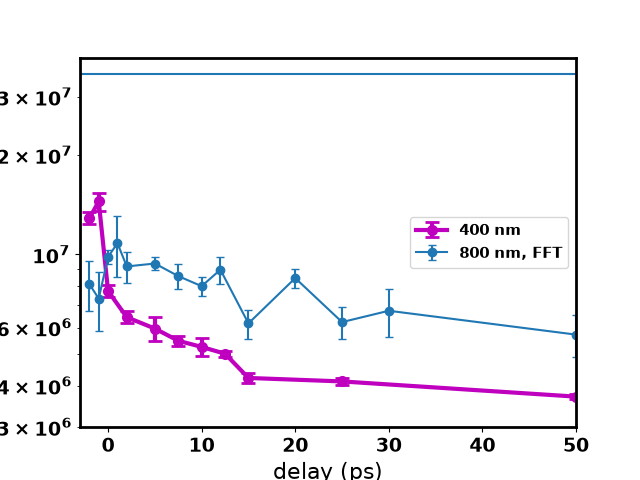

In [6]:
plt.figure()
# plt.errorbar(sigma800.keys(), [v["mean"] for v in sigma800.values()], fmt="-o", capsize=3, label="800 nm, peak")
plt.errorbar(FFTsigma400.keys(), [v["mean"] for v in FFTsigma400.values()], yerr=[v["std"] for v in FFTsigma400.values()], color="m", fmt="-o", capsize=5, capthick=2, markersize=7, label="400 nm", lw=3)
plt.errorbar(FFT800.keys(), [v["mean"] for v in FFT800.values()], yerr=[v["std"] for v in FFT800.values()], fmt="-o", capsize=3, label="800 nm, FFT")

#plt.errorbar(FFT800.keys(), [v["mean"] for v in FFT800.values()], fmt="-o", capsize=3, label="800 nm, FFT")
#plt.errorbar(FFT800_5.keys(), [v["mean"] for v in FFT800_5.values()], fmt="-o", capsize=3, label="800 nm, FFT (5ps)", zorder=3)
#plt.errorbar(FFT800_4.keys(), [v["mean"] for v in FFT800_4.values()], fmt="-o", capsize=5, capthick=2, markersize=7, label="800 nm, 4 ps", lw=1.5)
plt.legend()
plt.axhline(y=(.35e8))
plt.yscale('log')
plt.xlabel("delay (ps)")
plt.ylabel("conductivity (S/m)")
plt.xlim(-3,50)


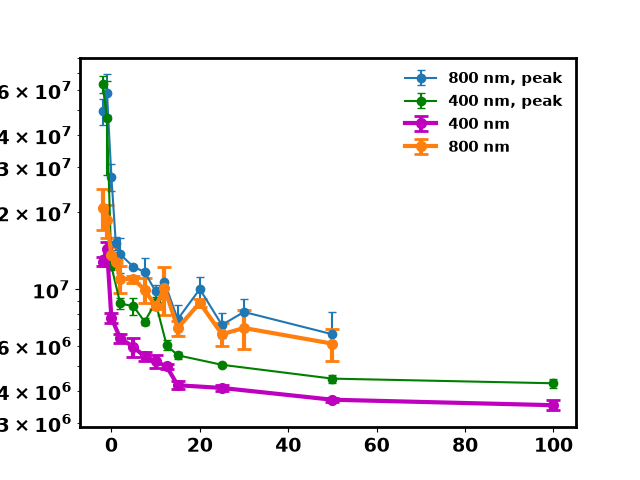

In [7]:
plt.figure()

plt.errorbar(sigma800.keys(), [v["mean"] for v in sigma800.values()], yerr=[v["std"] for v in sigma800.values()], fmt="-o", capsize=3, label="800 nm, peak")
plt.errorbar(sigma400.keys(), [v["mean"] for v in sigma400.values()], yerr=[v["std"] for v in sigma400.values()], color="g",fmt="-o", capsize=3, label="400 nm, peak")

plt.errorbar(FFTsigma400.keys(), [v["mean"] for v in FFTsigma400.values()], yerr=[v["std"] for v in FFTsigma400.values()], color="m", fmt="-o", capsize=5, capthick=2, markersize=7, label="400 nm", lw=3)
plt.errorbar(FFT800_4.keys(), [v["mean"] for v in FFT800_4.values()], yerr=[v["std"] for v in FFT800_4.values()], fmt="-o", capsize=5, capthick=2, markersize=7, label="800 nm", lw=3)


plt.legend(edgecolor='none')
plt.yscale('log')

# plot thz waveform

--------------------------------
File path: /Users/yuewang/SLAC/goldthz/Au_data/400nm/processed_data/single_shot/SS_Au_wpneg17_pos10_2_shot_0001/
creating plot for file: /Users/yuewang/SLAC/goldthz/Au_data/400nm/processed_data/single_shot/SS_Au_wpneg17_pos10_2_shot_0001/
Post_bal : (667,) Shot_bal : (667,) Time_axis : (667,)


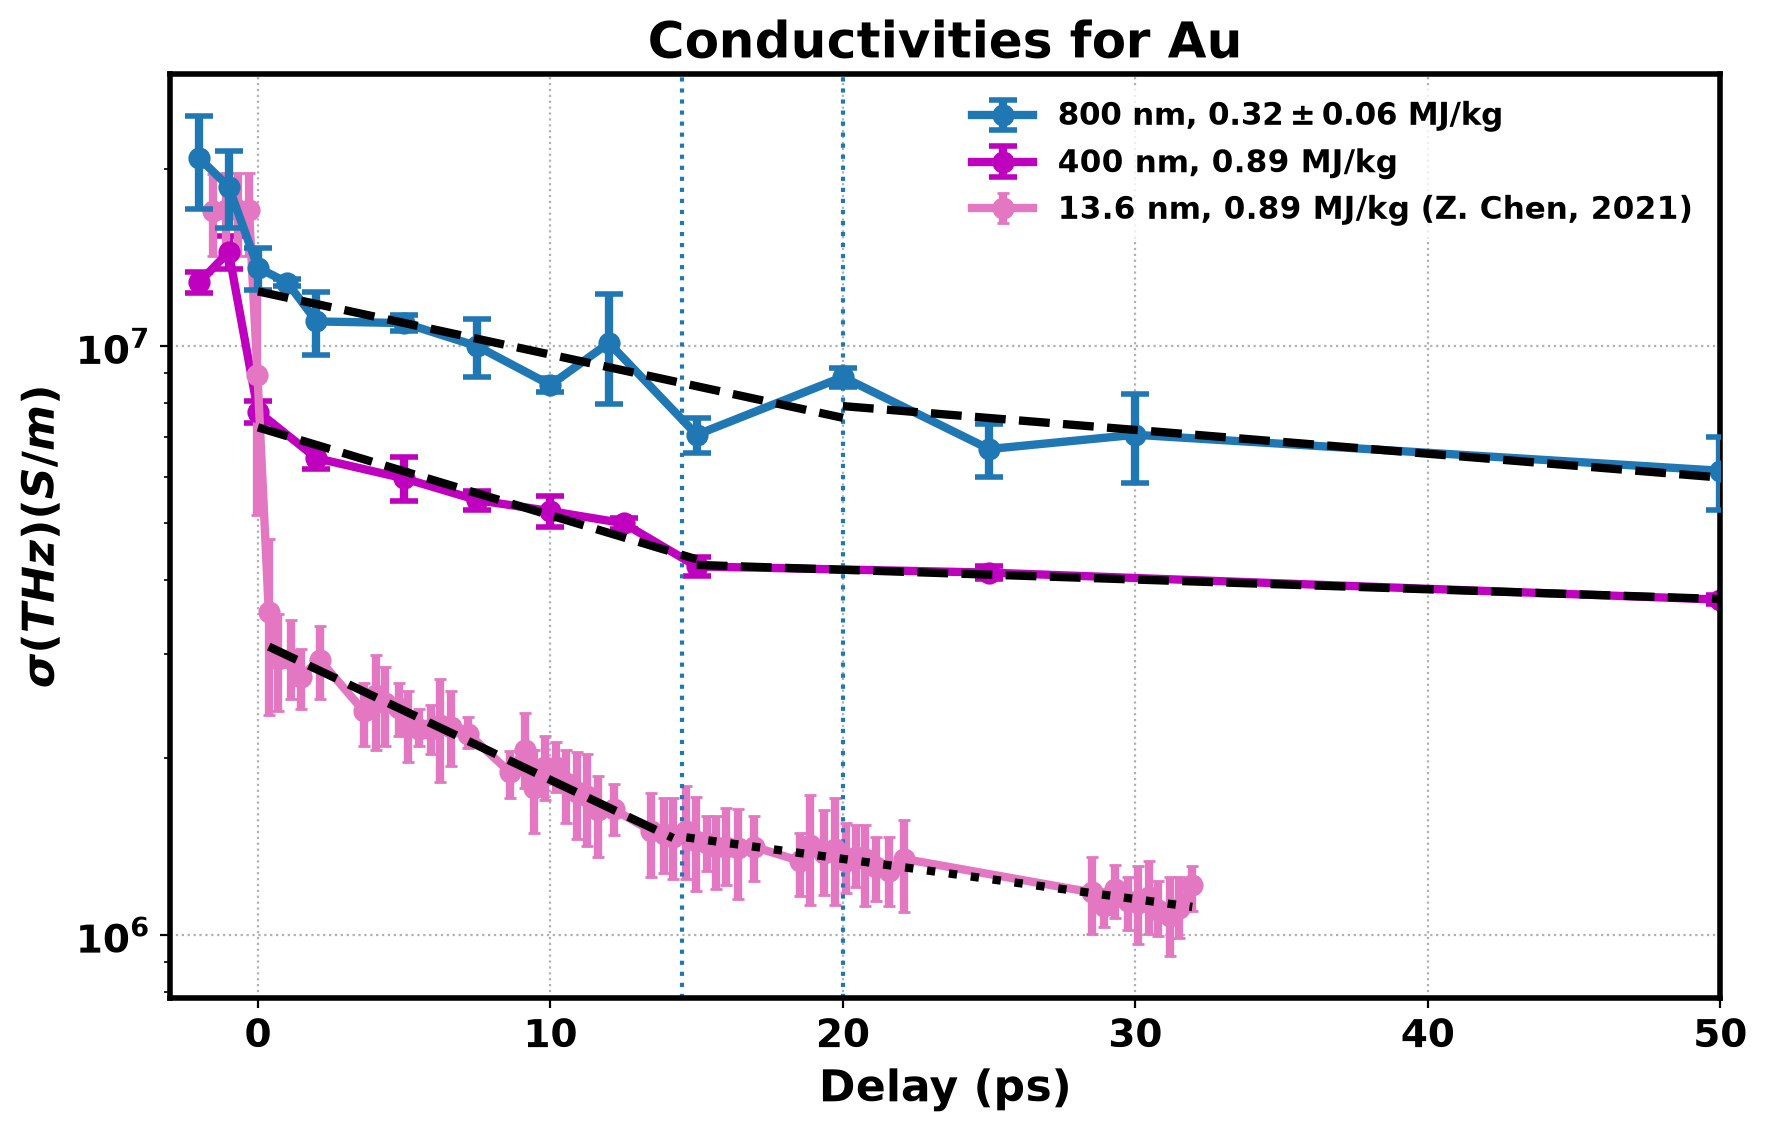

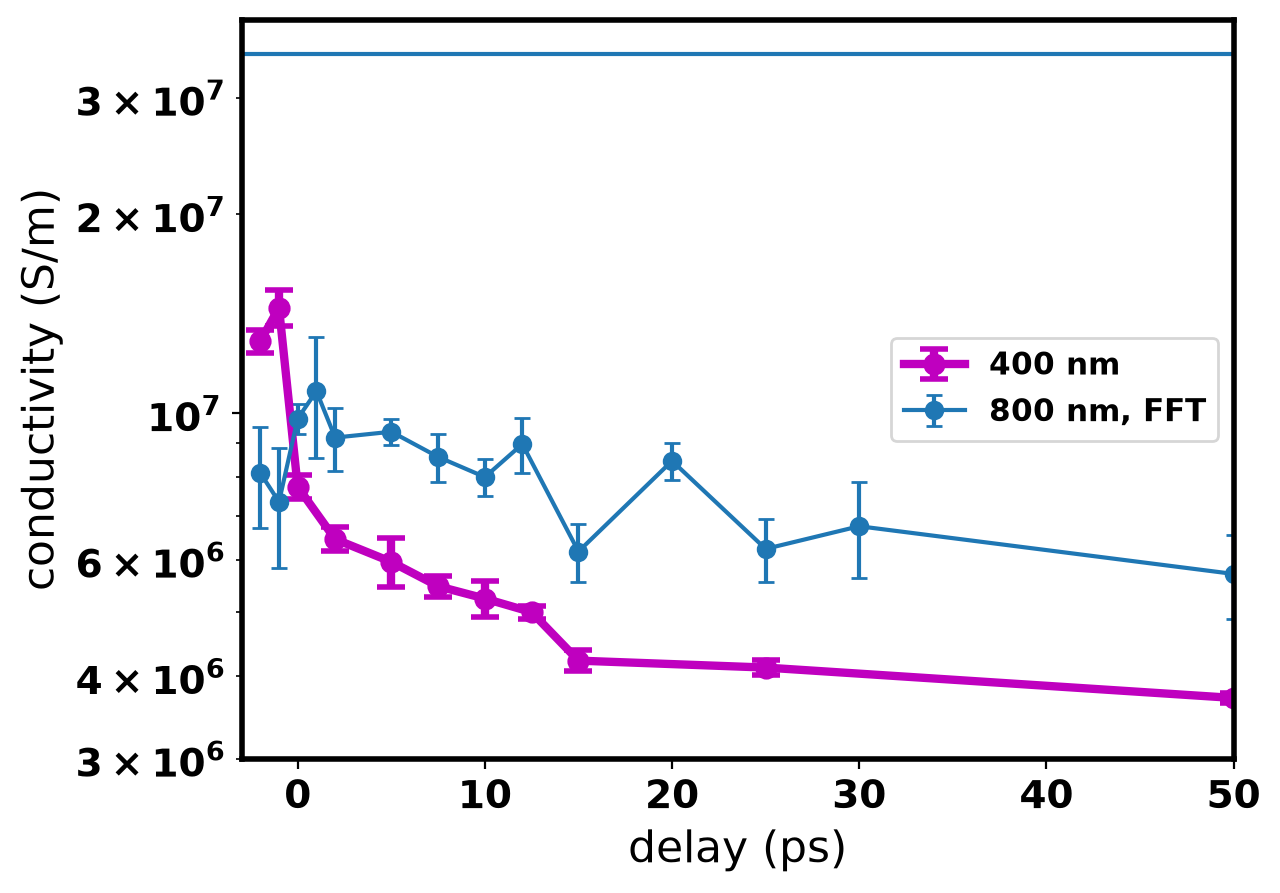

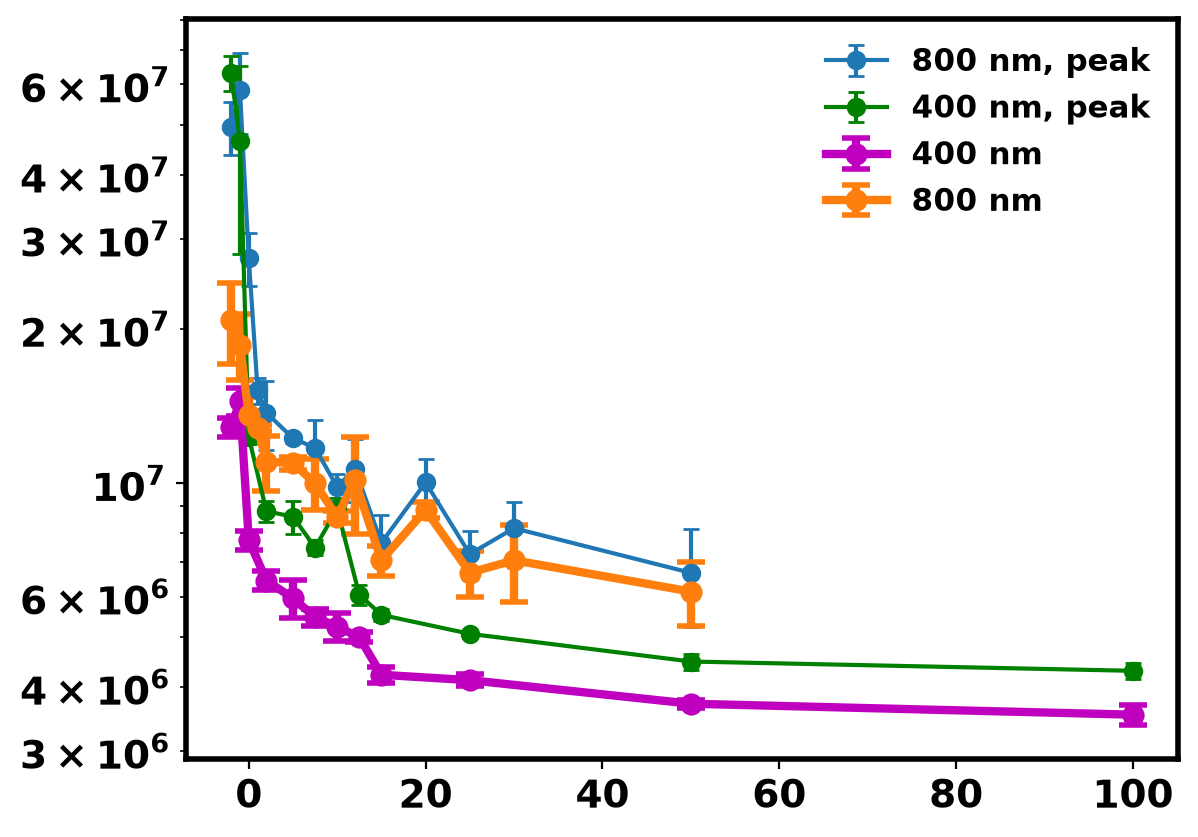

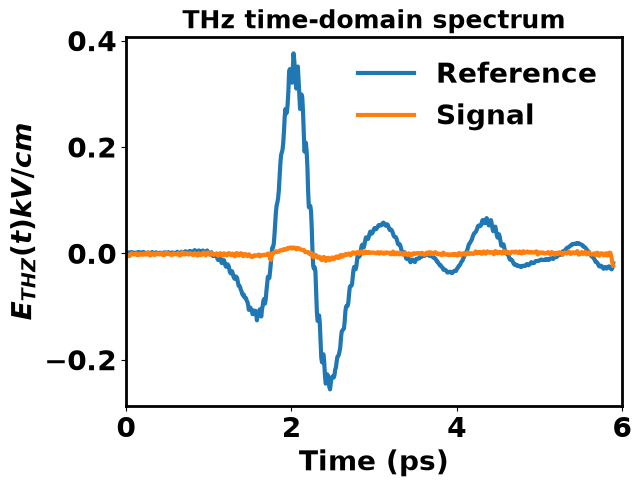

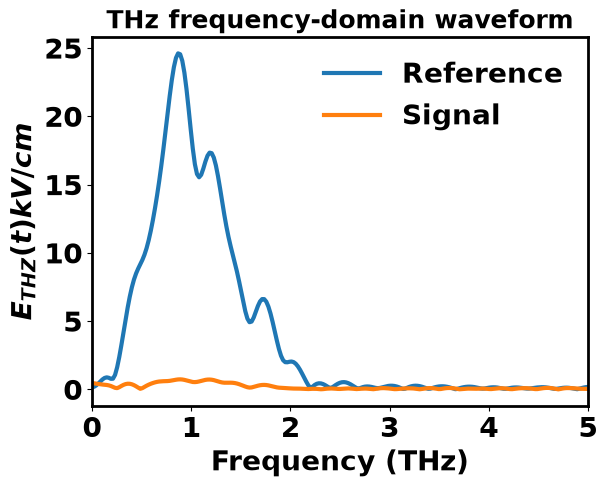

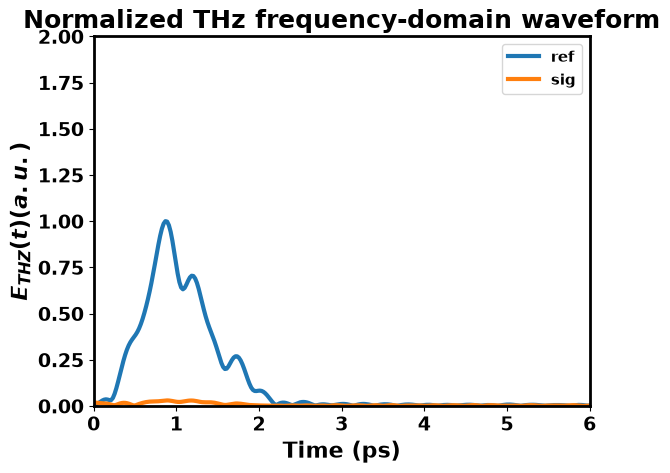

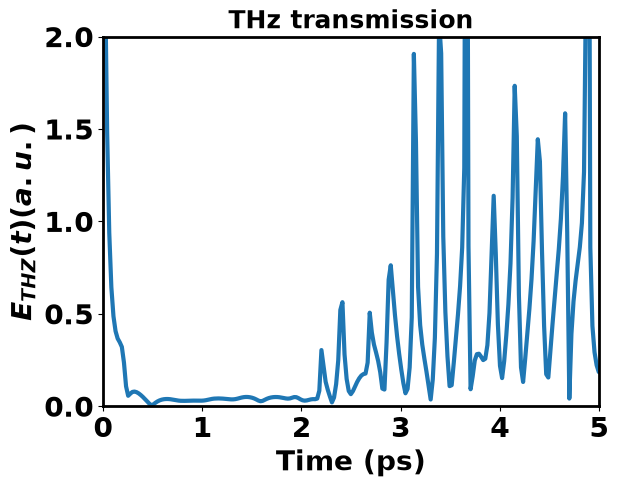

In [8]:
import os
import numpy.fft as fft
file_root = '/Users/yuewang/SLAC/goldthz/Au_data/400nm/processed_data/single_shot/'
%matplotlib inline

def create_plot(path, wp, pos, num):
    file_path = file_root + path
    post_bal_raw = np.loadtxt(file_path + 'THz_post_bal.dat')
    post_bal = np.mean(post_bal_raw, axis=1)  # average over the columns
    shot_bal = np.loadtxt(file_path + 'THz_shot_bal.dat')
    time_axis = np.loadtxt(file_path + 'time_axis.dat')

    size = 20

    x, y, z = post_bal.shape, shot_bal.shape, time_axis.shape
    print("Post_bal :", x, "Shot_bal :", y, "Time_axis :", z)

    plt.figure()
    plt.plot(time_axis, post_bal, "-",lw=3, label="Reference") # plot only the 1st column of post_bal
    plt.plot(time_axis, shot_bal, "-",lw=3, label="Signal")
    plt.xlabel("Time (ps)", weight="bold", fontsize=size)
    plt.xlim(0,6)
    plt.ylabel(r"$E_{THZ}(t) kV/cm$", weight="bold", fontsize=size)
    plt.title(f"THz time-domain spectrum", weight="bold")
    plt.legend(edgecolor="none", fontsize=size)
    plt.tick_params(axis='both', labelsize=size)

    plt.show()


    # compute frequency axis 
    dt = time_axis[1] - time_axis[0]
    N = len(time_axis)

    # zero padding
    Nfft = 5336 # 8 times number of data points

    # padded fft
    ref_fft = fft.fft(post_bal, n=Nfft)
    sig_fft = fft.fft(shot_bal, n=Nfft)
    trans_fft = sig_fft / ref_fft

    freq = fft.fftfreq(Nfft, dt)
    # sort by frequency
    index = np.argsort(freq)
    frq_sort = freq[index]
    ref_sort = ref_fft[index]
    sig_sort = sig_fft[index]
    transfer = sig_sort/ref_sort

    plt.figure()
    plt.plot(frq_sort, np.abs(ref_sort), lw=3, label="Reference")
    plt.plot(frq_sort, np.abs(sig_sort), lw=3, label="Signal")

    plt.title("THz frequency-domain waveform", weight="bold")
    plt.ylabel(r"$E_{THZ}(t) kV/cm$", weight="bold", fontsize=size)
    plt.xlabel("Frequency (THz)", weight="bold", fontsize=size)
    plt.tick_params(axis='both', labelsize=size)
    plt.legend(edgecolor="none", fontsize=size)
    plt.xlim(0, 5)

    max = np.max(np.abs(ref_sort))
    refNorm = np.abs(ref_sort)/max
    sigNorm = np.abs(sig_sort)/max
    plt.figure()
    plt.plot(frq_sort, np.abs(refNorm), lw=3, label="ref")
    plt.plot(frq_sort, np.abs(sigNorm), lw=3, label="sig")

    plt.title("Normalized THz frequency-domain waveform", weight="bold")
    plt.ylabel(r"$E_{THZ}(t) (a.u.)$", weight="bold")
    plt.xlabel("Time (ps)", weight="bold")
    plt.legend()

    plt.ylim(0,2)
    plt.xlim(0, 6)

    transNorm = sigNorm/refNorm
    plt.figure()
    plt.plot(frq_sort, np.abs(transNorm), lw=3, label="Transmission")

    plt.title("THz transmission", weight="bold")
    plt.ylabel(r"$E_{THZ}(t) (a.u.)$", weight="bold", fontsize=size)
    plt.xlabel("Time (ps)", weight="bold", fontsize=size)
    plt.tick_params(axis='both', labelsize=size)

    plt.ylim(0,2)
    plt.xlim(0, 5)

def cycle_through(position: str, p_range, wp):
    for digit in p_range:
        pos = position + str(digit)

        shot_num = 1
        for shot in range(shot_num):
            num = '{:0>4}'.format(int(shot + 1))
            path = 'SS_Au_' + wp + '_' + pos + '_shot_' + num + "/"
            file_path = file_root + path

            print("--------------------------------")
            print(f"File path: {file_path}")
            if not os.path.exists(file_path):
                print(f"File path does not exist: {file_path}")
                continue
            else:
                print(f"creating plot for file: {file_path}")
                create_plot(path, wp, pos, num)

#cycle_through("neg", [i for i in range(3)])
#cycle_through("pos", [1, 2, 5, '7p5', 10, '12p5', 15, 20, 25, '30_3', 30, 50, '50_3'])
cycle_through("pos", ["10_2"], "wpneg17")